<a href="https://colab.research.google.com/github/eduzegarra/grade_01/blob/main/info_06_empresas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import pandas as pd
os.chdir('/content/drive/MyDrive/a_SENAMHI/OUT/')
!ls


base_final.csv	     comercio.dta    informacion.dta  supag.dta
caracteristicas.dta  coord_prod.csv  mq_eq.dta	      top_regions.csv
caratulas.dta	     costos.dta      riego.dta	      vbpagri.dta
cofert.dta	     edu.dta	     sf.dta


In [3]:
df = pd.read_csv('base_final.csv', low_memory=False)

In [4]:
### nos quedamos con observaciones validas para info_5 y t_vbpagri

df_val=df.loc[(df.info_5.notna()) & (df.t_vbpagri.notna()) ].copy()

In [6]:
columns_to_fill = df_val.filter(regex=r'maq|equ|t_comprador|t_destino').columns
df_val[columns_to_fill] = df_val[columns_to_fill].fillna(0)

In [7]:
df_val['t_ingagri'] = (df_val.t_vbpagri - df_val.cost_tot).astype(float)

In [8]:
# Create dummy variables for REGION, dropping the first category to avoid multicollinearity
region_dummies = pd.get_dummies(df_val['REGION'], prefix='region', drop_first=True, dtype=float)
year_dummies = pd.get_dummies(df_val['ANIO'], prefix='year', drop_first=True, dtype=float)

# Join both region and year dummies back to our main enterprise dataframe as a list
df_val = df_val.join([region_dummies, year_dummies])


In [9]:
## Convertimos algunas variables a logaritmos

import numpy as np
ll=['ingagri', 'vbpagri', 'supcose', 'supag']
for dd in ll:
  # Using np.maximum(0, ...) to guarantee that the input to log1p is non-negative and avoid warnings
  df_val['log_'+dd] = np.log1p(df_val['t_'+dd])

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [10]:
## excluimos cuando ingreso neto agrario es negativo
df_val.loc[df_val.log_ingagri<0, 'log_ingagri'] = np.nan

In [11]:
df_val.filter(regex='log').describe().transpose()

,count,mean,std,min,25%,50%,75%,max
log_ingagri,47032.0,2.389077,1.689148,0.000000,1.090496,2.199444,3.380723,13.879978
log_vbpagri,97726.0,1.729344,1.806384,0.000000,0.000000,1.269761,2.903617,13.993067
log_supcose,97726.0,1.084367,1.014395,0.000300,0.357674,0.774727,1.504077,9.924872
log_supag,97726.0,1.749845,1.189516,0.001998,0.875052,1.504077,2.351375,10.757924


In [12]:
### ESTIMACION GENERAL OLS PARA EMPRESAS

!pip install -q linearmodels
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

# 1. Create separate DataFrames for Empresas and Productores with explicit copies
df_emp = df_val.loc[df_val['tipo'] == 'Empresa'].copy()

# 2. Define independent variables lists
region_cols = ['region_Sierra', 'region_Selva']
year_cols = ['year_2025']

# Note: based on previous cell edits, the column name is t_usoequ (or t_usoequip/t_usoequ depending on data)
# Let's dynamically find the correct usage column name for equipment
# usoequ_col = 't_usoequ' if 't_usoequ' in df_val.columns else 't_usoequip'

vars_common = ['info_5', 'log_supcose', 't_usomaq', 't_usoequ',
               't_afectacion', 't_destino3', 't_credito', 't_riego']
vars_emp = vars_common + region_cols + year_cols

# Clean missing values for each model subset specifically
model_vars_emp = ['log_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM', 'log_supag'] + vars_emp
base_emp = df_emp.dropna(subset=model_vars_emp).copy()

# Add constants explicitly for IV estimation
base_emp['const'] = 1.0

# --- EMPRESAS MODEL ---
print("=== EMPRESAS (COMPANIES) ===")
# Weighted OLS using WLS
formula_emp = f"log_vbpagri ~ {' + '.join(vars_emp)}"
wls_emp = smf.wls(formula_emp, data=base_emp,
                  weights=base_emp['FACTOR_PRODUCTOR']).fit(cov_type='HC1')
print(wls_emp.summary())

# IV-2SLS Endogeneity Test
exog_emp = ['const'] + [v for v in vars_emp if v != 'info_5']
iv_emp = IV2SLS(dependent=base_emp['log_vbpagri'],
                 exog=base_emp[exog_emp],
                 endog=base_emp['info_5'],
                 instruments=base_emp[['neces_AGROCLIM', 'log_supag']],
                 weights=base_emp['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print("\n--- Endogeneity Test (Empresas) ---")
print(iv_emp.wu_hausman())


=== EMPRESAS (COMPANIES) ===
                            WLS Regression Results                            
Dep. Variable:            log_vbpagri   R-squared:                       0.732
Model:                            WLS   Adj. R-squared:                  0.731
Method:                 Least Squares   F-statistic:                     886.6
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:56:24   Log-Likelihood:                -4645.9
No. Observations:                2227   AIC:                             9316.
Df Residuals:                    2215   BIC:                             9384.
Df Model:                          11                                         
Covariance Type:                  HC1                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        

In [13]:
### MODELO IV-2SLS PARA EMPRESAS

from linearmodels.iv import IV2SLS

region_cols = ['region_Sierra', 'region_Selva']
year_cols = ['year_2025']


# Define the exogenous variables matching the variables defined in Eof3BfZp3gvn
exog_vars = ['const', 'log_supcose', 't_usomaq', 't_usoequ', 't_afectacion', 't_destino3', 't_credito', 't_riego'] + region_cols + year_cols

# Run the IV-2SLS model with FACTOR_PRODUCTOR as weights, using 2 instruments
iv_model = IV2SLS(
    dependent=base_emp['log_vbpagri'],
    exog=base_emp[exog_vars],
    endog=base_emp['info_5'],
    instruments=base_emp[['neces_AGROCLIM', 'log_supag']],
    weights=base_emp['FACTOR_PRODUCTOR']
).fit(cov_type='robust')

print(iv_model.summary)

                          IV-2SLS Estimation Summary                          
Dep. Variable:            log_vbpagri   R-squared:                      0.7180
Estimator:                    IV-2SLS   Adj. R-squared:                 0.7166
No. Observations:                2227   F-statistic:                    8839.1
Date:                Thu, Oct 22 2026   P-value (F-stat)                0.0000
Time:                        10:56:47   Distribution:                 chi2(11)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const            -0.3228     0.2430    -1.3283     0.1841     -0.7992      0.1535
log_supcose       0.8245     0.0446     

In [15]:
### MODELO IV-2SLS PARA EMPRESAS (EN NIVELES)

from linearmodels.iv import IV2SLS
import pandas as pd
import numpy as np

region_cols = ['region_Sierra', 'region_Selva']
year_cols = ['year_2025']

# Definir las variables comunes y exógenas usando variables en niveles (sin transformación logarítmica)
vars_levels = ['info_5', 't_supcose', 't_usomaq', 't_usoequ', 't_afectacion', 't_destino3', 't_credito', 't_riego'] + region_cols + year_cols

# Variables requeridas para la estimación en niveles
model_vars_levels = ['t_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM', 't_supag'] + vars_levels

# Limpiar valores nulos sobre este subconjunto específico
base_emp_levels = df_emp.dropna(subset=model_vars_levels).copy()
base_emp_levels['const'] = 1.0

exog_vars_levels = ['const', 't_supcose', 't_usomaq', 't_usoequ', 't_afectacion', 't_destino3', 't_credito', 't_riego'] + region_cols + year_cols

# Estimar el modelo IV-2SLS en niveles usando t_supag como instrumento para info_5
iv_model_levels = IV2SLS(
    dependent=base_emp_levels['t_vbpagri'],
    exog=base_emp_levels[exog_vars_levels],
    endog=base_emp_levels['info_5'],
    instruments=base_emp_levels[['neces_AGROCLIM', 't_supag']],
    weights=base_emp_levels['FACTOR_PRODUCTOR']
).fit(cov_type='robust')

print(iv_model_levels.summary)

                          IV-2SLS Estimation Summary                          
Dep. Variable:              t_vbpagri   R-squared:                      0.2357
Estimator:                    IV-2SLS   Adj. R-squared:                 0.2319
No. Observations:                2227   F-statistic:                    171.23
Date:                Thu, Oct 22 2026   P-value (F-stat)                0.0000
Time:                        10:57:25   Distribution:                 chi2(11)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const            -6390.5     3056.3    -2.0910     0.0365  -1.238e+04     -400.36
t_supcose         27.532     5.6964     

In [16]:
# Analizar la distribución detallada de t_vbpagri para identificar outliers
percentiles_vbp = base_emp_levels['t_vbpagri'].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999])
print("=== Percentiles de t_vbpagri (Empresas) ===")
print(percentiles_vbp)

# Obtener estadísticas descriptivas adicionales de la variable en niveles
print("\n=== Estadísticas Descriptivas de t_vbpagri ===")
display(base_emp_levels['t_vbpagri'].describe())

=== Percentiles de t_vbpagri (Empresas) ===
0.500       335.210000
0.750      3717.387000
0.900     26053.303600
0.950     62146.186300
0.990    280682.767980
0.995    443127.682500
0.999    933222.201312
Name: t_vbpagri, dtype: float64

=== Estadísticas Descriptivas de t_vbpagri ===


,t_vbpagri
count,2.227000e+03
mean,1.513437e+04
std,6.719674e+04
min,0.000000e+00
25%,3.950000e+00
50%,3.352100e+02
75%,3.717387e+03
max,1.194294e+06


In [17]:
# 1. Definir el umbral de corte (Percentil 95)
cutoff = base_emp_levels['t_vbpagri'].quantile(0.95)
print(f"Umbral de exclusión (Percentil 95): S/. {cutoff:,.2f}")

# 2. Filtrar la base excluyendo outliers
base_emp_no_outliers = base_emp_levels[base_emp_levels['t_vbpagri'] <= cutoff].copy()
print(f"Observaciones antes del filtro: {len(base_emp_levels)}")
print(f"Observaciones después del filtro: {len(base_emp_no_outliers)}")

# 3. Re-estimar el modelo IV-2SLS en niveles
iv_model_no_outliers = IV2SLS(
    dependent=base_emp_no_outliers['t_vbpagri'],
    exog=base_emp_no_outliers[exog_vars_levels],
    endog=base_emp_no_outliers['info_5'],
    instruments=base_emp_no_outliers[['neces_AGROCLIM', 't_supag']],
    weights=base_emp_no_outliers['FACTOR_PRODUCTOR']
).fit(cov_type='robust')

print("\n=== MODELO IV-2SLS EN NIVELES (SIN OUTLIERS > P95) ===")
print(iv_model_no_outliers.summary)

Umbral de exclusión (Percentil 95): S/. 62,146.19
Observaciones antes del filtro: 2227
Observaciones después del filtro: 2115

=== MODELO IV-2SLS EN NIVELES (SIN OUTLIERS > P95) ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:              t_vbpagri   R-squared:                      0.2032
Estimator:                    IV-2SLS   Adj. R-squared:                 0.1990
No. Observations:                2115   F-statistic:                    395.26
Date:                Thu, Oct 22 2026   P-value (F-stat)                0.0000
Time:                        10:57:47   Distribution:                 chi2(11)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
----------------------

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from linearmodels.iv import IV2SLS

# 1. Identificar los top 5 cultivos principales de la submuestra de empresas
top_crops = base_emp['t_cultprinc'].value_counts().head(5).index.tolist()
print("Top 5 cultivos identificados:", top_crops)

results = []

# Definir variables exógenas de control en logaritmos EXCLUYENDO las dummies regionales
exog_sin_regiones = ['const', 'log_supcose', 't_usomaq', 't_usoequ', 't_afectacion', 't_destino3', 't_credito', 'year_2025']

for crop in top_crops:
    # Filtrar por cultivo usando la base con transformación logarítmica completa
    df_crop = base_emp[base_emp['t_cultprinc'] == crop].copy()

    # Filtrar dinámicamente variables exógenas que no tengan variación
    # Esto evita problemas de rango incompleto (colinealidad perfecta)
    exog_dynamic = []
    for var in exog_sin_regiones:
        if var == 'const':
            exog_dynamic.append(var)
        elif df_crop[var].nunique() > 1:
            exog_dynamic.append(var)
        else:
            print(f"[{crop}] Variable excluida por falta de variación: {var}")

    # Estimar el modelo si hay suficientes observaciones
    if len(df_crop) > 30:
        try:
            model = IV2SLS(
                dependent=df_crop['log_vbpagri'],
                exog=df_crop[exog_dynamic],
                endog=df_crop['info_5'],
                instruments=df_crop[['neces_AGROCLIM', 'log_supag']],
                weights=df_crop['FACTOR_PRODUCTOR']
            ).fit(cov_type='robust')

            coef = model.params['info_5']
            std_err = model.std_errors['info_5']
            p_val = model.pvalues['info_5']
            ci_lower = model.conf_int().loc['info_5', 'lower']
            ci_upper = model.conf_int().loc['info_5', 'upper']

            results.append({
                'cultivo': crop,
                'coef': coef,
                'std_err': std_err,
                'p_value': p_val,
                'ci_lower': ci_lower,
                'ci_upper': ci_upper,
                'n': len(df_crop)
            })
        except Exception as e:
            print(f"No se pudo estimar para {crop}: {e}")
    else:
        print(f"Muestra insuficiente para el cultivo: {crop} (N={len(df_crop)})")

# Crear un DataFrame con los resultados recopilados
df_res = pd.DataFrame(results)
display(df_res)

Top 5 cultivos identificados: ['PALTO', 'PASTO', 'MANGO', 'MANDARINA', 'VID']


,cultivo,coef,std_err,p_value,ci_lower,ci_upper,n
0,PALTO,-0.074744,0.480603,0.876411,-1.016709,0.867221,301
1,PASTO,-0.454750,0.760021,0.549614,-1.944364,1.034864,240
2,MANGO,1.958927,0.979815,0.045578,0.038525,3.879329,186
3,MANDARINA,-0.037361,0.583864,0.948978,-1.181713,1.106990,149
4,VID,-0.905749,1.632359,0.578983,-4.105113,2.293616,144


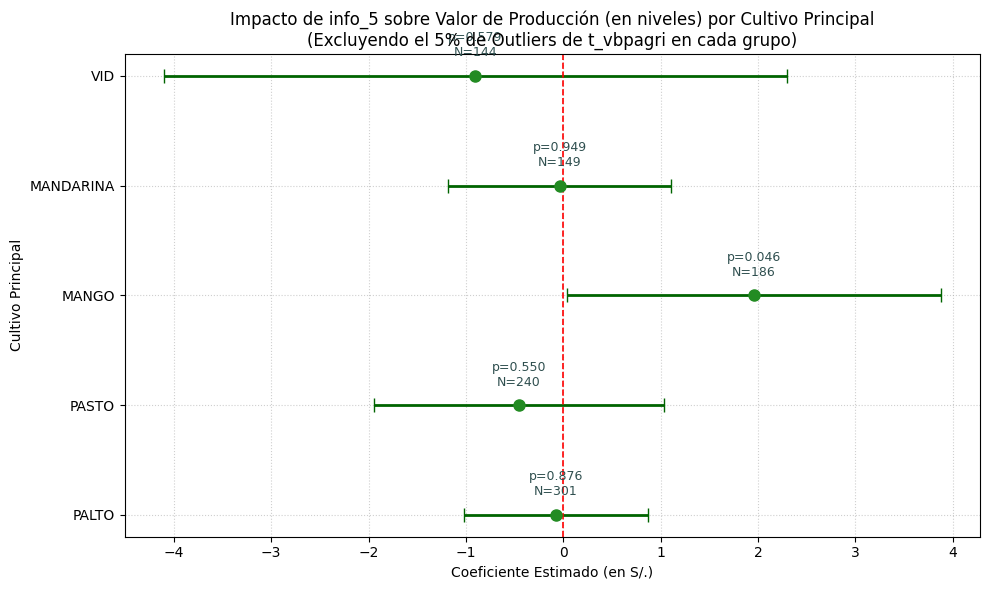

In [19]:
# 2. Graficar los coeficientes de cada cultivo principal con su intervalo de confianza
plt.figure(figsize=(10, 6))

# Generar gráfico de barras de error (Point plot con barras de error)
for i, row in df_res.iterrows():
    plt.errorbar(x=row['coef'], y=row['cultivo'],
                 xerr=[[row['coef'] - row['ci_lower']], [row['ci_upper'] - row['coef']]],
                 fmt='o', color='forestgreen', ecolor='darkgreen', elinewidth=2, capsize=5, ms=8)

    # Añadir etiqueta de p-valor al lado del punto central
    plt.text(row['coef'], i + 0.15, f"p={row['p_value']:.3f}\nN={row['n']}",
             ha='center', va='bottom', fontsize=9, color='darkslategray')

plt.axvline(x=0, color='red', linestyle='--', linewidth=1.2)
plt.title("Impacto de info_5 sobre Valor de Producción (en niveles) por Cultivo Principal\n(Excluyendo el 5% de Outliers de t_vbpagri en cada grupo)", fontsize=12)
plt.xlabel("Coeficiente Estimado (en S/.)")
plt.ylabel("Cultivo Principal")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()